# Ok-k-mer

Use python310 conda environment

## Imports

In [1]:
import os
# from random import randint
from random import sample
from random import sample, seed as set_seed, randint
import numpy as np
import pandas as pd
from collections import Counter
from ete3 import Tree
from itertools import combinations, product
from scipy.stats import binom, geom, spearmanr, pearsonr

pd.options.display.max_rows = 40

In [2]:
# import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mplpatches
%matplotlib inline

plt.rcParams['figure.dpi'] = 300
plt.rcParams['agg.path.chunksize'] = 10000

In [3]:
# import plotnine

from plotnine import \
    ggplot, aes, theme, themes, element_blank, element_line, element_text, mapping, \
    geom_point, geom_jitter, geom_line, geom_bar, geom_boxplot, geom_violin, geom_histogram, \
    ggtitle, xlab, ylab, geom_vline, geom_hline, geom_abline, geom_col, geom_tile, \
    scale_x_discrete, scale_y_discrete, scale_x_continuous, scale_y_continuous, \
    scale_color_discrete, scale_fill_manual, scale_fill_hue, scale_fill_gradient, scale_color_manual, scale_color_hue, \
    guides, after_stat, \
    xlim, ylim
from plotnine.options import figure_size
from mizani.formatters import percent_format

# plotnine theme
def theme_tufte_func(base_size=19, base_family="sans", rotate=True, figure_size=None):
    ''' Plotnine plotting theme. '''
    thm = themes.theme_bw(base_size=base_size, base_family = base_family) + \
        theme(
            legend_background = element_blank(),
            legend_key = element_blank(),
            panel_background = element_blank(),
            panel_border = element_blank(),
            strip_background = element_blank(),
            plot_background = element_blank(),
            panel_grid = element_blank(),
            axis_line = element_line(colour = "black", size = 1),
            axis_text_y = element_text(colour = "black")
        )

    if rotate:
        thm += theme(axis_text_x=element_text(rotation=45, hjust=1))
    if figure_size is not None:
        thm += theme(figure_size=figure_size)
    return thm


## Helper functions

In [4]:
def yield_file_lines(path):
    ''' Read file from path line-by-line. '''
    with open(path, 'r') as in_file:
        for line in in_file:
            yield line.strip()

In [5]:
def calc_corr(l1, l2, pearson=False, prnt=False):
    if pearson:
        corr, pval = pearsonr(l1, l2)
    else:
        corr, pval = spearmanr(l1, l2)
    if prnt:
        print("Correlation coefficient:", corr)
        print("p-value:", pval)
    return corr, pval

In [6]:
def dist_tree_calc(filename1):
    ''' Calculate tree distance. '''
    tree1= Tree(filename1,format=1)
    # print('Tree from', filename1, 'len:', len(tree1))
    dist_tree={}
    samples = [i.name for i in tree1.get_leaves()]
    num_sample = len(samples)
    for i in range(num_sample):
        tax_i = samples[i]
        for j in range(i+1,num_sample):
            tax_j = samples[j]
            dist_tree[(min(tax_i, tax_j)+".fa", max(tax_i, tax_j)+".fa")] = tree1.get_distance(tax_i, tax_j, topology_only=False)
    # print('num samples:', num_sample)
    # print('xxx:', num_sample * (num_sample-1)/2)
    # print('tree len:', len(dist_tree))
    return dist_tree


In [7]:
def make_tree_dict(tree_path):
    """
    Given a path to a Newick tree file, return a symmetric dictionary of distances between all pairs of taxa names
    (with or without '.fa' extension).

    Parameters:
        tree_path (str): Path to the Newick tree file.

    Returns:
        dict: A dictionary of dictionaries: { taxon_name: { other_taxon: distance, ... }, ... }
    """
    dist_tree = dist_tree_calc(tree_path)

    names = set()
    processed_pairs = []
    for (g1, g2), dist in dist_tree.items():
        g1_clean = g1.rstrip('.fa')
        g2_clean = g2.rstrip('.fa')
        names.add(g1_clean)
        names.add(g2_clean)
        processed_pairs.append((g1_clean, g2_clean, float(dist)))

    tree_dict = {name: {other: 0.0 for other in names} for name in names}
    for g1, g2, d in processed_pairs:
        tree_dict[g1][g2] = d
        tree_dict[g2][g1] = d  # Ensure symmetry

    return tree_dict


In [8]:

def get_random_samples(sample_names, sample_fraction=0.1, seed=None):
    '''
    # Example usage:
    cyano_random_samples = get_random_samples(cyano_sample_names, sample_fraction=0.1, seed=42)
    '''
    if seed is not None:
        set_seed(seed)
    num_samples = max(1, int(len(sample_names) * sample_fraction))
    random_samples = sample(sample_names, num_samples)
    return random_samples



In [9]:
def parse_dashing_dfs(dir_path):
    """
    Parses all distance_* files in the given directory into a dictionary of pandas DataFrames.
    Each DataFrame skips the first line, assumes tab-separation and adjusts indices and columns as expected.

    Args:
        dir_path (str): Path to the directory containing distance_* files.

    Returns:
        dict: Dictionary mapping filename to corresponding DataFrame.
    """

    # Get list of files in directory that start with 'distance_'
    files = [f for f in os.listdir(dir_path) if os.path.isfile(os.path.join(dir_path, f)) and f.startswith('distance_')]

    # Create a dictionary to store dataframes
    dashing_dfs = {}

    # Read each file into a dataframe, skipping first line
    for file in files:
        file_path = os.path.join(dir_path, file)
        try:
            # Skip first line and read tab-separated data
            df = pd.read_csv(file_path, sep='\t', header=None, skiprows=1)
            df.index = df.iloc[:, 0].str.replace('genomes_ncbi/', '')
            df = df.iloc[:, 1:]
            df.columns = df.index
            dashing_dfs[file] = df
            # print(f"Successfully read {file}")
        except Exception as e:
            print(f"Error reading {file}: {str(e)}")

    # Print summary of loaded dataframes
    print(f"\nLoaded {len(dashing_dfs)} files")
    for file, df in dashing_dfs.items():
        print(f"{file}: {df.shape}")
    return dashing_dfs

In [10]:
def build_merged_df(tree_dict, dashing_dfs):
    """
    Build merged dataframe for all genome pairs among `genomes`,
    including tree distances and distances for each k from `dashing_dfs`.

    Parameters:
    -----------
    tree_dict : dict
        Nested dictionary of tree-based distances; tree_dict[g1][g2] gives distance.
    dashing_dfs : dict
        Mapping from dashing file name to pairwise distance DataFrame.

    Returns:
    --------
    merged_df : pd.DataFrame
        DataFrame indexed by sorted genome pairs, with metadata and k-mer distances.
    """

    genomes = sorted(tree_dict.keys())

    # Create all pairs of genomes (upper triangle only, sorted lexicographically)
    pairs = []
    for i in range(len(genomes)):
        for j in range(i+1, len(genomes)):
            pair = '_'.join(sorted([genomes[i], genomes[j]]))
            pairs.append(pair)

    # Initialize dataframe with pairs as index
    merged_df = pd.DataFrame(index=pairs)

    # Add metadata columns to merged_df
    genome_pairs = []
    genomes_1s = []
    genomes_2s = []
    tree_distances = []
    for index in merged_df.index:
        # Split the genome pair
        genome1 = "_".join(index.split("_", 2)[:2])
        genome2 = "_".join(index.split("_", 2)[2:])

        # Get distance from tree_dict
        genome_pairs.append(index)
        genomes_1s.append(genome1)
        genomes_2s.append(genome2)
        tree_distances.append(tree_dict[genome1][genome2])

    merged_df['genome_pair'] = genome_pairs
    merged_df['genome_1'] = genomes_1s
    merged_df['genome_2'] = genomes_2s
    merged_df['tree_distance'] = tree_distances

    print(f"Final dataframe shape: {merged_df.shape}")

    # For each k, add a column to merged_df with the pairwise distances
    for fname, df in dashing_dfs.items():
        k_val = int(str(fname).replace('distance_k', '').replace('.txt', ''))
        # Build a dictionary mapping sorted genome pair -> distance
        pair_to_dist = {}
        for i in range(len(df)):
            g1 = df.iloc[i].name
            for g2, d in dict(df.iloc[i]).items():
                if g1 == g2: continue
                pair = '_'.join(sorted([g1, g2]))
                pair_to_dist[pair] = d

        # Map the distances to the merged_df for this k
        colname = f'k{k_val}_distance'
        merged_df[colname] = merged_df.index.map(pair_to_dist.get)
        print(f"Added column '{colname}' to merged_df.")

    return merged_df

In [11]:
def process_data(tree_path, dashing_dir_path):
    tree_dict = make_tree_dict(tree_path)
    dashing_dfs = parse_dashing_dfs(dashing_dir_path)
    merged_df = build_merged_df(tree_dict, dashing_dfs)
    return tree_dict, dashing_dfs, merged_df


In [12]:
# cyano_sample_names = sorted(cyano_nwk_dict.keys())
# chlam_sample_names = sorted(chlam_nwk_dict.keys())
# len(cyano_sample_names), len(chlam_sample_names)
# cyano_random_samples = get_random_samples(cyano_sample_names, sample_fraction=0.1, seed=42)

## Process data

In [13]:
aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/dashingfull_genomes_ncbi'
bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/dashingfull_genomes_ncbi'
caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/dashingfull_genomes_ncbi'
chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/dashingfull_genomes_ncbi'
cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/dashingfull_genomes_ncbi'
neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/dashingfull_genomes_ncbi'

aquificota_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/f__Neisseriaceae.nwk'

chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = process_data(chlamydia_tree_path, chlamydia_dir_path)
aquificota_tree_dict, aquificota_dashing_dfs, aquificota_merged_df = process_data(aquificota_tree_path, aquificota_dir_path)
bacillales_tree_dict, bacillales_dashing_dfs, bacillales_merged_df = process_data(bacillales_tree_path, bacillales_dir_path)
caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_merged_df = process_data(caldisericia_tree_path, caldisericia_dir_path)
cyano_tree_dict, cyano_dashing_dfs, cyano_merged_df = process_data(cyano_tree_path, cyano_dir_path)
neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_merged_df = process_data(neisseriaceae_tree_path, neisseriaceae_dir_path)

Error reading distance_k33.txt: No columns to parse from file

Loaded 28 files
distance_k10.txt: (288, 288)
distance_k11.txt: (288, 288)
distance_k12.txt: (288, 288)
distance_k13.txt: (288, 288)
distance_k14.txt: (288, 288)
distance_k15.txt: (288, 288)
distance_k16.txt: (288, 288)
distance_k17.txt: (288, 288)
distance_k18.txt: (288, 288)
distance_k19.txt: (288, 288)
distance_k20.txt: (288, 288)
distance_k21.txt: (288, 288)
distance_k22.txt: (288, 288)
distance_k23.txt: (288, 288)
distance_k24.txt: (288, 288)
distance_k25.txt: (288, 288)
distance_k26.txt: (288, 288)
distance_k27.txt: (288, 288)
distance_k28.txt: (288, 288)
distance_k29.txt: (288, 288)
distance_k30.txt: (288, 288)
distance_k31.txt: (288, 288)
distance_k32.txt: (288, 288)
distance_k5.txt: (288, 288)
distance_k6.txt: (288, 288)
distance_k7.txt: (288, 288)
distance_k8.txt: (288, 288)
distance_k9.txt: (288, 288)
Final dataframe shape: (41328, 4)
Added column 'k10_distance' to merged_df.
Added column 'k11_distance' to merged_

## Analyze corrrelation

In [14]:
# spearman rank for k to true distance for all pairs

def spearman_corr_against_tree(dfs_dict, tree_dict, sample_mask=[]):
    rows = []
    for fname, df in dfs_dict.items():
        # Derive k from filename when possible
        k_val = int(str(fname).replace('distance_k', '').replace('.txt', ''))
        names = list(df.index)
        x_dashing = []
        y_tree = []

        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                raw1, raw2 = names[i], names[j]
                g1 = raw1.replace('genomes_ncbi/', '').rstrip('.fa')
                g2 = raw2.replace('genomes_ncbi/', '').rstrip('.fa')
                # Only analyze samples not in sample_mask
                if (g1 in sample_mask) or (g2 in sample_mask):
                    continue
                td = tree_dict[g1][g2]
                dashing_dist = float(df.loc[raw1, raw2])
                x_dashing.append(dashing_dist)
                y_tree.append(float(td))

        corr, pval = spearmanr(x_dashing, y_tree)
        rows.append({
            'k': k_val,
            'spearman_corr': corr,
            'p_value': pval,
            'n_pairs': len(x_dashing)
        })

    return pd.DataFrame(rows)


In [ ]:
# cyano_mask_samples = get_random_samples(cyano_sample_names, sample_fraction=0.1, seed=42)
# chlam_mask_samples = get_random_samples(chlam_sample_names, sample_fraction=0.1, seed=42)
# len(cyano_mask_samples), len(chlam_mask_samples)


NameError: name 'cyano_sample_names' is not defined

In [ ]:
# chlam_corr_df_mask = spearman_corr_against_tree(chlam_dashing_dfs, chlam_nwk_dict, chlam_mask_samples)

# Sort by numeric k when possible
# if 'k' in chlam_corr_df_mask.columns:
    # chlam_corr_df_mask = chlam_corr_df_mask.sort_values('k')

# chlam_corr_df_mask

NameError: name 'chlam_dashing_dfs' is not defined

## 2+ k-mer correlation

In [15]:
def compute_kmer_avg_rank_corr(merged_df, k_ref=20):
    """
    Calculate Spearman correlations between tree distances and the *average rank*
    of a reference k-mer (default k=20) and all other k-mers in merged_df.

    Args:
        merged_df (pd.DataFrame): DataFrame with k-mer distances and tree_distance.
        k_ref (int, optional): Reference k-mer value (default=20).

    Returns:
        Tuple (k_values, combined_corrs, single_k_corrs)
            - k_values (list of int): k-mer values used (looped).
            - combined_corrs (list of float): Spearman correlations of avg. rank (k_ref & k).
            - single_k_corrs (list of float): Spearman correlations of single k only.
    """

    k_ref_ranks = merged_df[f'k{k_ref}_distance'].rank()

    k_values = []
    combined_corrs = []
    single_k_corrs = []

    for k in range(5, 33):
        k_mid_ranks = merged_df[f'k{k}_distance'].rank()
        avg_ranks = (k_mid_ranks + k_ref_ranks) / 2
        corr, pval = calc_corr(avg_ranks, merged_df['tree_distance'], prnt=False)
        print(f"k={k_ref},{k}: {corr}, {pval}")

        single_k_corr, _ = calc_corr(k_mid_ranks, merged_df['tree_distance'], prnt=False)

        k_values.append(k)
        combined_corrs.append(corr)
        single_k_corrs.append(single_k_corr)

    return k_values, combined_corrs, single_k_corrs


In [16]:

def plot_kmer_avg_rank_corr(k_values, combined_corrs, single_k_corrs, k_ref=20):
    """
    Plot the Spearman correlations as a function of k (single and averaged k-mer ranks).

    Args:
        k_values (list): List of k values.
        combined_corrs (list): Spearman correlations for average of k_ref & k.
        single_k_corrs (list): Spearman correlations for single k.
        title (str, optional): Plot title. If None, generates a default title using k_ref.
        k_ref (int, optional): Reference k-mer value (default=20).
    """

    combined_label = f"(k, {k_ref})-mer average"
    single_label = "Single k-mer"

    plot_df = pd.DataFrame({
        'k_value': k_values,
        'Combined k': combined_corrs,
        single_label: single_k_corrs
    })

    plot_df = pd.melt(plot_df,
                      id_vars=['k_value'],
                      value_vars=['Combined k', single_label],
                      var_name='Method',
                      value_name='correlation')

    plot_df['Method'] = plot_df['Method'].replace({single_label: single_label, 'Combined k': combined_label})

    plot = (
        ggplot(plot_df) +
        geom_point(aes(x='k_value', y='correlation', color='Method'), alpha=0.8) +
        geom_line(aes(x='k_value', y='correlation', color='Method', group='Method'), alpha=0.8) +
        ggtitle(f"Dashing Jaccard index:\nSingle k-mer and (k, {k_ref})-mer average") +
        xlab("k-mer Jaccard length") +
        ylab("Spearman correlation") +
        theme_tufte_func(base_size=15, rotate=False, figure_size=(8, 5)) +
        scale_x_continuous(breaks=range(5,33,2)) +
        scale_color_manual(values=['#000000', '#D7263D'],
                          breaks=[single_label, combined_label])
    )
    return plot


In [17]:

# tree_dict =
# tree_dict =
# spearman_corr_against_tree(dfs_dict, tree_dict)

# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = process_data(chlamydia_tree_path, chlamydia_dir_path)
spearman_corr_against_tree(chlamydia_dashing_dfs, chlamydia_tree_dict)


/tmp/ipykernel_2016425/2278004018.py:25: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.


,k,spearman_corr,p_value,n_pairs
0,10,-0.344365,0.000000e+00,41328
1,11,-0.341808,0.000000e+00,41328
2,12,-0.291268,0.000000e+00,41328
3,13,-0.243907,0.000000e+00,41328
4,14,-0.228658,0.000000e+00,41328
5,15,-0.247307,0.000000e+00,41328
6,16,-0.304448,0.000000e+00,41328
7,17,-0.366936,0.000000e+00,41328
8,18,-0.398111,0.000000e+00,41328
9,19,-0.418595,0.000000e+00,41328


k=23,5: -0.698469637136924, 0.0
k=23,6: -0.698469637136924, 0.0
k=23,7: -0.6990298323382885, 0.0
k=23,8: -0.4598236967885044, 0.0
k=23,9: -0.47829313126756506, 0.0
k=23,10: -0.5264285489841093, 0.0
k=23,11: -0.5702784650543486, 0.0
k=23,12: -0.5727902362108572, 0.0
k=23,13: -0.5732296272037366, 0.0
k=23,14: -0.5824296986451096, 0.0
k=23,15: -0.6004681266193658, 0.0
k=23,16: -0.6257610294921394, 0.0
k=23,17: -0.6513948782865829, 0.0
k=23,18: -0.671771488724292, 0.0
k=23,19: -0.6843163027799688, 0.0
k=23,20: -0.6912551694310475, 0.0
k=23,21: -0.6956852281497259, 0.0
k=23,22: -0.6976278076953074, 0.0
k=23,23: -0.698469637136924, 0.0
k=23,24: -0.6986324780805152, 0.0


/tmp/ipykernel_2016425/2107416139.py:5: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.


k=23,25: -0.6981524342843938, 0.0
k=23,26: -0.6972930986153184, 0.0
k=23,27: -0.6960448484671206, 0.0
k=23,28: -0.6948657187166338, 0.0
k=23,29: -0.693506947082278, 0.0
k=23,30: -0.6919559399073655, 0.0
k=23,31: -0.6904990361735708, 0.0
k=23,32: -0.6889560866213216, 0.0


/home/shwang45/miniconda3/envs/python310/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 2 rows containing missing values.


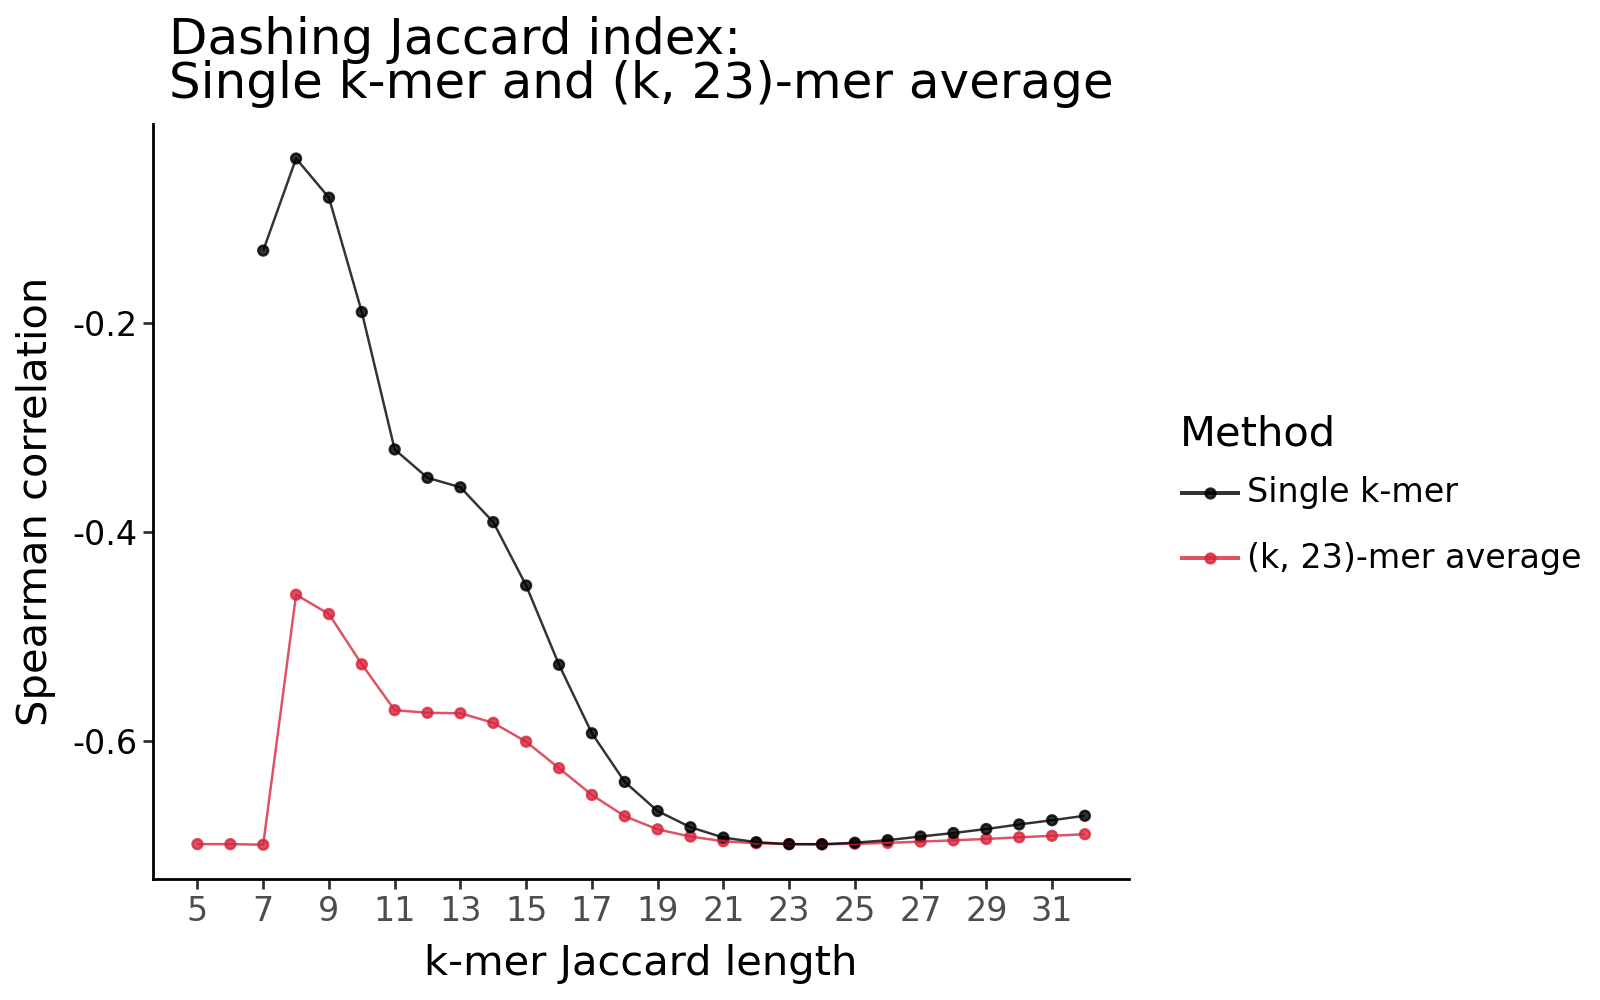

In [18]:
k_ref = 23
merged_df = bacillales_merged_df

k_values, combined_corrs, single_k_corrs = compute_kmer_avg_rank_corr(merged_df, k_ref)
plot_kmer_avg_rank_corr(k_values, combined_corrs, single_k_corrs, k_ref)

In [ ]:
# asdf



In [19]:
chlamydia_merged_df
aquificota_merged_df
bacillales_merged_df
caldisericia_merged_df
cyano_merged_df
neisseriaceae_merged_df

,genome_pair,genome_1,genome_2,tree_distance,k10_distance,k26_distance,k11_distance,k22_distance,k7_distance,k14_distance,...,k32_distance,k20_distance,k6_distance,k17_distance,k23_distance,k8_distance,k28_distance,k9_distance,k5_distance,k27_distance
GCA_000176735.1_GCA_000952795.1,GCA_000176735.1_GCA_000952795.1,GCA_000176735.1,GCA_000952795.1,0.087946,0.760883,0.031206,0.494572,0.040219,1.000000,0.105971,...,0.022050,0.046198,1.000000,0.059021,0.037662,0.997111,0.027692,0.947057,1,0.029320
GCA_000176735.1_GCA_001067655.1,GCA_000176735.1_GCA_001067655.1,GCA_000176735.1,GCA_001067655.1,0.085027,0.764904,0.029599,0.497369,0.037947,1.000000,0.102141,...,0.021108,0.043513,1.000000,0.055596,0.035577,0.997233,0.026344,0.949193,1,0.027854
GCA_000176735.1_GCA_002777825.1,GCA_000176735.1_GCA_002777825.1,GCA_000176735.1,GCA_002777825.1,0.427084,0.709826,0.000863,0.384369,0.001112,1.000000,0.019893,...,0.000663,0.001332,1.000000,0.002261,0.001034,0.996990,0.000782,0.941344,1,0.000819
GCA_000176735.1_GCA_003028315.1,GCA_000176735.1_GCA_003028315.1,GCA_000176735.1,GCA_003028315.1,0.089758,0.762226,0.030580,0.495143,0.039301,1.000000,0.104405,...,0.021710,0.045122,1.000000,0.057707,0.036826,0.997324,0.027180,0.947531,1,0.028752
GCA_000176735.1_GCA_016864895.1,GCA_000176735.1_GCA_016864895.1,GCA_000176735.1,GCA_016864895.1,0.659344,0.570616,0.000510,0.264123,0.000622,0.998901,0.011497,...,0.000387,0.000704,0.999519,0.001114,0.000591,0.987201,0.000463,0.877750,1,0.000486
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GCF_946478525.1_GCF_962719845.1,GCF_946478525.1_GCF_962719845.1,GCF_946478525.1,GCF_962719845.1,0.429201,0.680859,0.000293,0.349719,0.000436,1.000000,0.015522,...,0.000194,0.000567,1.000000,0.001191,0.000389,0.995135,0.000252,0.931408,1,0.000269
GCF_946478525.1_GCF_962747995.1,GCF_946478525.1_GCF_962747995.1,GCF_946478525.1,GCF_962747995.1,0.433818,0.679830,0.000299,0.349573,0.000439,1.000000,0.015742,...,0.000205,0.000572,1.000000,0.001210,0.000393,0.995531,0.000260,0.931311,1,0.000277
GCF_946902045.1_GCF_962719845.1,GCF_946902045.1_GCF_962719845.1,GCF_946902045.1,GCF_962719845.1,0.078664,0.751149,0.026498,0.481637,0.033620,1.000000,0.091228,...,0.019341,0.038527,1.000000,0.049374,0.031586,0.995195,0.023741,0.940756,1,0.025012
GCF_946902045.1_GCF_962747995.1,GCF_946902045.1_GCF_962747995.1,GCF_946902045.1,GCF_962747995.1,0.083280,0.748799,0.022689,0.478153,0.029246,1.000000,0.085441,...,0.016165,0.033768,1.000000,0.043964,0.027368,0.995469,0.020171,0.939293,1,0.021327


# Scratch

In [27]:
# genomes =
from itertools import permutations

x = list(permutations(chlam_sample_names, 2))

In [ ]:
# Spearman rank correlation: average distance ranks vs. true tree distances

from scipy.stats import spearmanr

k1 = 11
k2 = 20

df1 = chlam_dashing_dfs['distance_k'+ str(k1) + '.txt']
df2 = chlam_dashing_dfs['distance_k'+ str(k2) + '.txt']

avg_ranks = []
tree_distances = []
pair_labels = []

for g1, g2 in x:
    # Average rank of the pair in both distance matrices
    d1 = df1.loc[g1, g2]
    d2 = df2.loc[g1, g2]
    flat_idx1 = df1.index.get_loc(g1) * len(df1.columns) + df1.columns.get_loc(g2)
    flat_idx2 = df2.index.get_loc(g1) * len(df2.columns) + df2.columns.get_loc(g2)
    d1_ranks = df1.values.flatten().argsort().argsort()
    d2_ranks = df2.values.flatten().argsort().argsort()
    d1_rank = d1_ranks[flat_idx1]
    d2_rank = d2_ranks[flat_idx2]
    d_avg = (d1_rank + d2_rank) / 2

    avg_ranks.append(d_avg)
    # Get true tree distance
    true_dist = chlam_nwk_dict[g1][g2]
    tree_distances.append(true_dist)
    pair_labels.append((g1, g2))

# Spearman rank correlation between d_avg and true tree distances
corr, p_value = spearmanr(avg_ranks, tree_distances)
print(corr, p_value)



-0.4885741793163473 0.0


In [ ]:


# Spearman rank correlation: average distance ranks vs. true tree distances

from scipy.stats import spearmanr

k1 = 11
k2 = 20

df1 = chlam_dashing_dfs['distance_k'+ str(k1) + '.txt']
df2 = chlam_dashing_dfs['distance_k'+ str(k2) + '.txt']

avg_ranks = []
tree_distances = []
pair_labels = []

for g1, g2 in x:
    # Average rank of the pair in both distance matrices
    d1 = df1.loc[g1, g2]
    d2 = df2.loc[g1, g2]
    flat_idx1 = df1.index.get_loc(g1) * len(df1.columns) + df1.columns.get_loc(g2)
    flat_idx2 = df2.index.get_loc(g1) * len(df2.columns) + df2.columns.get_loc(g2)
    d1_ranks = df1.values.flatten().argsort().argsort()
    d2_ranks = df2.values.flatten().argsort().argsort()
    d1_rank = d1_ranks[flat_idx1]
    d2_rank = d2_ranks[flat_idx2]
    d_avg = (d1_rank + d2_rank) / 2

    avg_ranks.append(d_avg)
    # Get true tree distance
    true_dist = chlam_nwk_dict[g1][g2]
    tree_distances.append(true_dist)
    pair_labels.append((g1, g2))

# Spearman rank correlation between d_avg and true tree distances
corr, p_value = spearmanr(avg_ranks, tree_distances)
print(corr, p_value)


In [ ]:
k_mid_ranks = merged_df[f'k_{k}'].rank()
avg_ranks = (k_mid_ranks + k20_ranks) / 2

In [ ]:
# for k=11, and 20 -0.4885741793163473 0.0

In [ ]:

# df_name = int(str(fname).replace('distance_k', '').replace('.txt', ''))
# g1, g2 = 'GCA_021372155.1', 'GCA_013813265.1'


# average of ranks of k
# g1

k1 = 11
k2 = 20

df1 = chlam_dashing_dfs['distance_k'+ str(k1) + '.txt']
df2 = chlam_dashing_dfs['distance_k'+ str(k2) + '.txt']

avg_rank_dict = dict()

for g1, g2 in x[:10]:
    d1 = df1.loc[g1, g2]
    d2 = df2.loc[g1, g2]
    d1_rank = df1.values.flatten().argsort().argsort()[df1.index.get_loc(g1) * len(df1.columns) + df1.columns.get_loc(g2)]
    d2_rank = df2.values.flatten().argsort().argsort()[df2.index.get_loc(g1) * len(df2.columns) + df2.columns.get_loc(g2)]
    d_avg = (d1_rank + d2_rank) / 2
    print(g1, g2, d_avg)





In [19]:
# 1. Find k indices where spearman_corr is a local minimum
from scipy.signal import argrelextrema
import numpy as np
from scipy.stats import spearmanr

# Assume chlam_corr_df is sorted by 'k'
corrs = chlam_corr_df['spearman_corr'].values
ks = chlam_corr_df['k'].values

# Find local minima (order=1 for adjacent points)
minima_idx = argrelextrema(corrs, np.less, order=1)[0]
local_minima_k = ks[minima_idx]

print("Local minima ks:", local_minima_k)

# 2. Calculate average ranks across the associated 'k's
# For each k in local_minima_k, get its index in chlam_corr_df
# Compute, for each sample: the average rank across all those ks
# We'll assume for the next step that there is a function or dataframe with per-sample values
# For demonstration, let's say chlam_dashing_dfs[k] is a dataframe for a given k, with index/sample and 'distance' column.

# Get list of "distance" values (distance matrices) for each minimum k
distance_matrices = [chlam_dashing_dfs[k] for k in local_minima_k]

# For a valid average-of-ranks, we'd usually compare all-against-all distances per sample.
# Let's flatten all off-diagonal distances for each matrix, then for each sample pair compute the mean rank
import pandas as pd

all_pairs = None
for k, df in zip(local_minima_k, distance_matrices):
    if isinstance(df, pd.DataFrame):
        mat = df.copy()
    else:
        mat = pd.DataFrame(df)
    dists = mat.values
    # Flatten and skip diagonal (self to self)
    mask = ~np.eye(dists.shape[0],dtype=bool)
    col = mat.columns if hasattr(mat, 'columns') else np.arange(dists.shape[0])
    row = mat.index if hasattr(mat, 'index') else np.arange(dists.shape[0])
    pairs = [(row[i], col[j], dists[i,j]) for i in range(dists.shape[0]) for j in range(dists.shape[1]) if i != j]
    tmp = pd.DataFrame(pairs, columns=['sample1', 'sample2', f'dist_{k}'])
    if all_pairs is None:
        all_pairs = tmp.set_index(['sample1', 'sample2'])
    else:
        all_pairs = all_pairs.join(tmp.set_index(['sample1', 'sample2']), how='inner')

# Now for each pair, take the average of the distances across used ks
all_pairs['avg_dist'] = all_pairs.mean(axis=1)
# Rank (average rank for each pair)
all_pairs['avg_dist_rank'] = all_pairs['avg_dist'].rank()

# Now, compare these ranks to the tree distances

# Create matching tree distances Series for sample pairs (assume chlam_nwk_dict has tree distances)
# We'll flatten the tree distances for each sample pair (match above order)

tree_dist_pairs = []
for i, name1 in enumerate(all_pairs.index.get_level_values(0)):
    name2 = all_pairs.index.get_level_values(1)[i]
    try:
        tree_dist = chlam_nwk_dict[name1][name2]
    except KeyError:
        tree_dist = chlam_nwk_dict[name2][name1]  # Try reverse
    tree_dist_pairs.append(tree_dist)
all_pairs['tree_dist'] = tree_dist_pairs
all_pairs['tree_dist_rank'] = all_pairs['tree_dist'].rank()

# Calculate Spearman's rank correlation between the average-of-ranks distances and tree ranks
spearman_corr, p_value = spearmanr(all_pairs['avg_dist_rank'], all_pairs['tree_dist_rank'])

print("Spearman correlation of average-of-ranks distances (at local minima ks) vs. tree distances:", spearman_corr)
print("p-value:", p_value)

Local minima ks: [10 20]


KeyError: 10

In [23]:
chlam_corr_df.loc[chlam_corr_df['spearman_corr'].idxmin()]

k                   20.000000
spearman_corr       -0.424038
p_value              0.000000
n_pairs          41328.000000
Name: 10, dtype: float64

In [24]:
chlam_corr_df_mask.loc[chlam_corr_df_mask['spearman_corr'].idxmin()]

k                   20.000000
spearman_corr       -0.422647
p_value              0.000000
n_pairs          33670.000000
Name: 10, dtype: float64

/home/shwang45/miniconda3/envs/python310/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 1 rows containing missing values.
/home/shwang45/miniconda3/envs/python310/lib/python3.10/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 1 rows containing missing values.


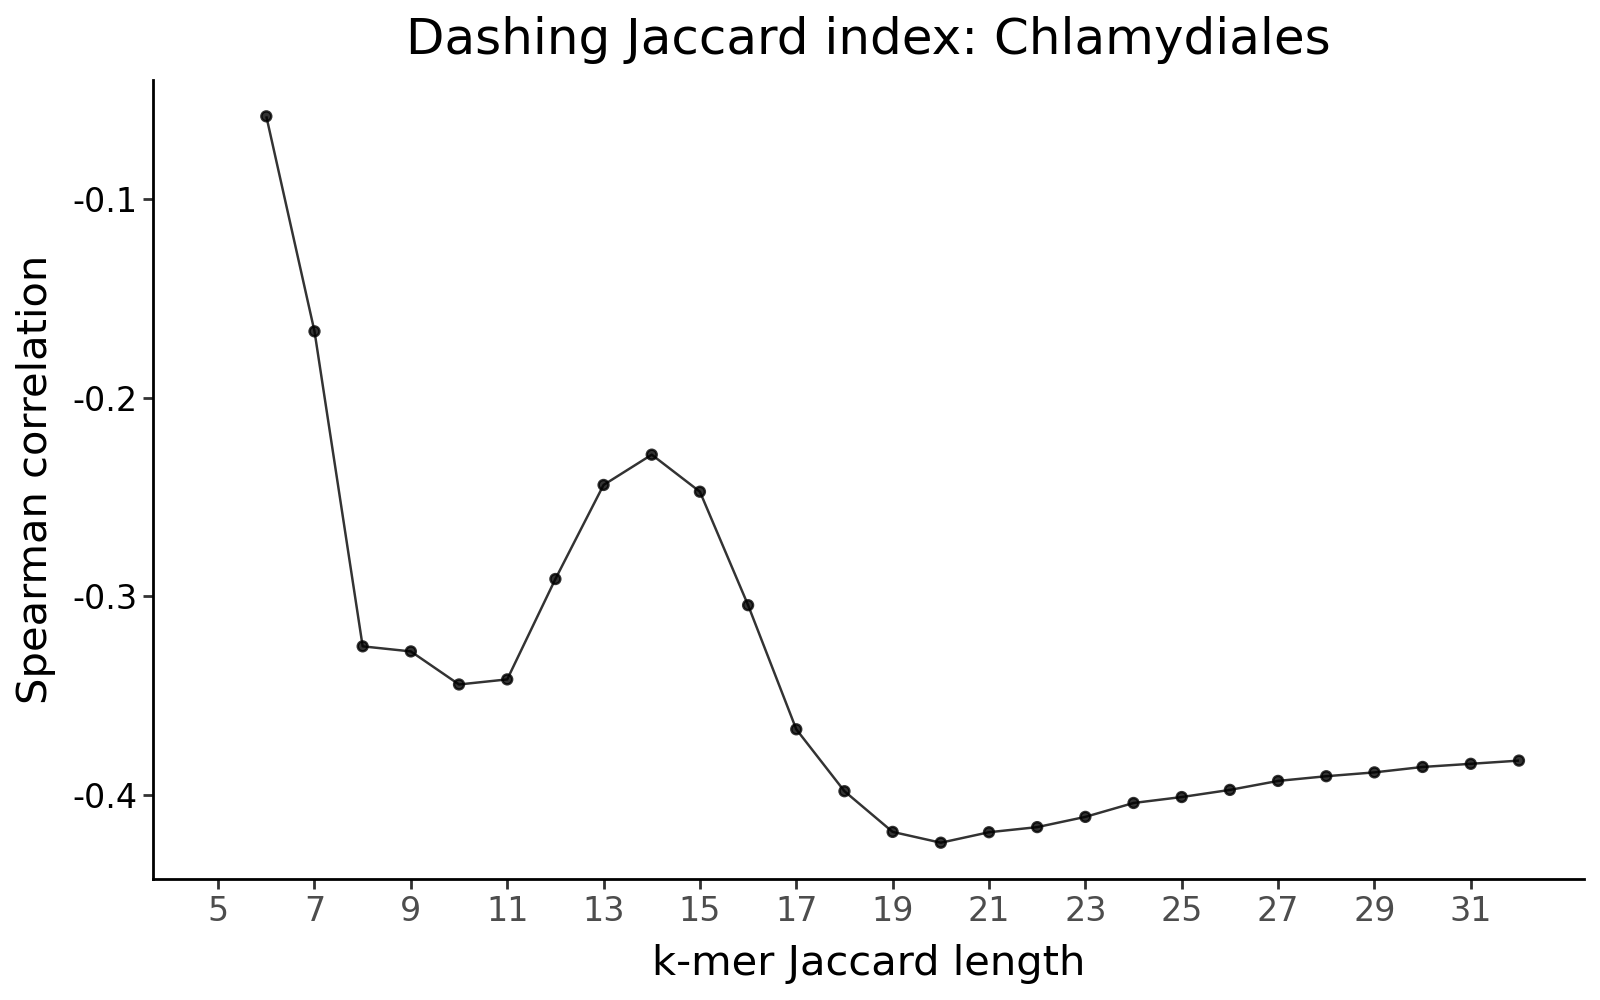

In [25]:
chlam_corr_df

(
    ggplot(chlam_corr_df) +
    geom_point(aes(x='k', y='spearman_corr'), alpha=0.8) +
    geom_line(aes(x='k', y='spearman_corr'), alpha=0.8) +
    # ggtitle("Dashing Jaccard index: Cyanobacteriales (n=585)") +
    ggtitle("Dashing Jaccard index: Chlamydiales") +
    xlab("k-mer Jaccard length") +
    ylab("Spearman correlation") +
    theme_tufte_func(base_size=15, rotate=False, figure_size=(8, 5)) +
    scale_x_continuous(breaks=range(5,33,2))
    # scale_x_continuous(breaks=range(5,33,2)) +
    # scale_color_manual(values=['#000000', '#D7263D'],  # Black, Royal blue, Green
                    #   breaks=['Single k', 'k and 20-mer'])  # Specify legend order
)

In [ ]:
# Filter for just the distance_k files and sort them by k value
distance_files = sorted([f for f in dashing_dfs.keys() if f.startswith('distance_k')],
                       key=lambda x: int(x.replace('distance_k', '').replace('.txt', '')))

# Create list of pairs and their distances
pairs = []
k_values = {}

# Process first file to get genome names and create pairs
first_df = dashing_dfs[distance_files[0]]
genomes = first_df.iloc[0, 1:].tolist()  # Get genome names from first row

# Clean genome names by removing 'genomes_ncbi/'
genomes = [g.replace('genomes_ncbi/', '') for g in genomes]

# Create all pairs of genomes (upper triangle only)
for i in range(len(genomes)):
    for j in range(i+1, len(genomes)):
        # Sort lexicographically and join with '_'
        pair = '_'.join(sorted([genomes[i], genomes[j]]))
        pairs.append(pair)

# Initialize dataframe with pairs as index
merged_df = pd.DataFrame(index=pairs)

# Add data from each distance file
for file in distance_files:
    k = int(file.replace('distance_k', '').replace('.txt', ''))
    df = dashing_dfs[file]

    # Extract distances for each pair
    distances = []
    for i in range(len(genomes)):
        for j in range(i+1, len(genomes)):
            distances.append(df.iloc[i+1, j+1])

    # Add as new column
    merged_df[f'k_{k}'] = distances

# Clean up the index name
merged_df.index.name = 'genome_pair'


# Add metadat columns to merged_df
genome_pairs = []
genomes_1s = []
genomes_2s = []
tree_distances = []

for index in merged_df.index:
    # Split the genome pair
    genome1 = "_".join(index.split("_", 2)[:2])
    genome2 = "_".join(index.split("_", 2)[2:])

    # Get distance from tree_dict
    distance = tree_dict[genome1][genome2]

    genome_pairs.append(index)
    genomes_1s.append(genome1)
    genomes_2s.append(genome2)
    tree_distances.append(distance)

# Add tree_distance column to merged_df
merged_df['genome_pair'] = genome_pairs
merged_df['genome_1'] = genomes_1s
merged_df['genome_2'] = genomes_2s
merged_df['tree_distance'] = tree_distances

print(f"Final dataframe shape: {merged_df.shape}")
merged_df


In [ ]:

# spearman rank for k to true distance for all pairs

def spearman_corr_against_tree(dfs_dict, tree_dict):
    rows = []
    for fname, df in dfs_dict.items():
        # Derive k from filename when possible
        try:
            k_val = int(str(fname).replace('distance_k', '').replace('.txt', ''))
        except Exception:
            k_val = fname

        names = list(df.index)
        x_dashing = []
        y_tree = []

        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                raw1, raw2 = names[i], names[j]
                g1 = raw1.replace('genomes_ncbi/', '').rstrip('.fa')
                g2 = raw2.replace('genomes_ncbi/', '').rstrip('.fa')

                # Fetch tree distance (symmetric)
                td = None
                if g1 in tree_dict and g2 in tree_dict[g1]:
                    td = tree_dict[g1][g2]
                elif g2 in tree_dict and g1 in tree_dict[g2]:
                    td = tree_dict[g2][g1]
                else:
                    continue  # skip pairs not present in the tree dict

                try:
                    dashing_dist = float(df.loc[raw1, raw2])
                except Exception:
                    # If labels aren't perfectly aligned, try the symmetric access
                    try:
                        dashing_dist = float(df.loc[raw2, raw1])
                    except Exception:
                        continue

                x_dashing.append(dashing_dist)
                y_tree.append(float(td))

        if len(x_dashing) >= 2:
            corr, pval = spearmanr(x_dashing, y_tree)
        else:
            corr, pval = np.nan, np.nan

        rows.append({
            'k': k_val,
            'spearman_corr': corr,
            'p_value': pval,
            'n_pairs': len(x_dashing)
        })

    return pd.DataFrame(rows)